APUESTAS EN JUEGO DE DADOS - MONTE CARLO <br>
Tu mejor amigo te invita a un juego de azar con apuestas para el proximo fin de semana y aun te quedan 3 dias para resolver si entras al juego.
El juego es de tirar un par de dados y se definen las siguientes reglas de ganancia y perdida:

Si obtienes en la suma de ambos dados un: 2, 3, 4, 9, 10, 11 0 12 ganas 20 pesos

Si obtienes en la suma de ambos dados un 5, 6, 7 u 8 pierdes 25 pesos.

Aun estas a tiempo para resolver si te conviene jugar o no, tu como ingeniero informatico decides hacer una simulacion de Montecarlo para resolver esta gran duda

SE SOLICITA
La simulacion de Monte Carlo para esta problematica planteada.
La interpretacion y recomendacion, basado y justificado por un grafico donde se muestre las veces de juego y sus ganacias/perdidas

In [440]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng()

In [441]:
def juego(numero_rondas: int):
    rng = np.random.default_rng()

    d1 = rng.integers(1, 7, size=numero_rondas)
    d2 = rng.integers(1, 7, size=numero_rondas)
    suma = d1 + d2

    sumas_ganadoras = [2, 3, 4, 9, 10, 11, 12]
    ganancia = np.where(np.isin(suma, sumas_ganadoras), 20, -25)
    ganancia_acumulada = np.cumsum(ganancia)

    df = pd.DataFrame({
        "dado_1": d1,
        "dado_2": d2,
        "suma": suma,
        "ganancia": ganancia,
        "ganancia_acumulada": ganancia_acumulada,
    })
    return df

In [442]:
N = 10000

df = juego(N)

df.head()

,dado_1,dado_2,suma,ganancia,ganancia_acumulada
0,3,3,6,-25,-25
1,3,6,9,20,-5
2,5,4,9,20,15
3,3,4,7,-25,-10
4,1,6,7,-25,-35


In [443]:
ganadoras = df["ganancia"] == 20
perdedoras = df["ganancia"] == -25

probabilidad_ganar_teorica = 16 / 36
probabilidad_perder_teorica = 20 / 36
valor_esperado = (probabilidad_ganar_teorica * 20) + (probabilidad_perder_teorica * -25)

resumen = {
    "Rondas simuladas": len(df),
    "Rondas con ganancia de $20": int(ganadoras.sum()),
    "Rondas con pérdida de $25": int(perdedoras.sum()),
    "Ganancia promedio simulada por ronda ($)": df["ganancia"].mean(),
    "Valor esperado teórico por ronda ($)": valor_esperado,
    "Ganancia/pérdida acumulada ($)": df["ganancia_acumulada"].iloc[-1],
}

pd.DataFrame([resumen]).T

,0
Rondas simuladas,10000.000
Rondas con ganancia de $20,4474.000
Rondas con pérdida de $25,5526.000
Ganancia promedio simulada por ronda ($),-4.867
Valor esperado teórico por ronda ($),-5.000
Ganancia/pérdida acumulada ($),-48670.000


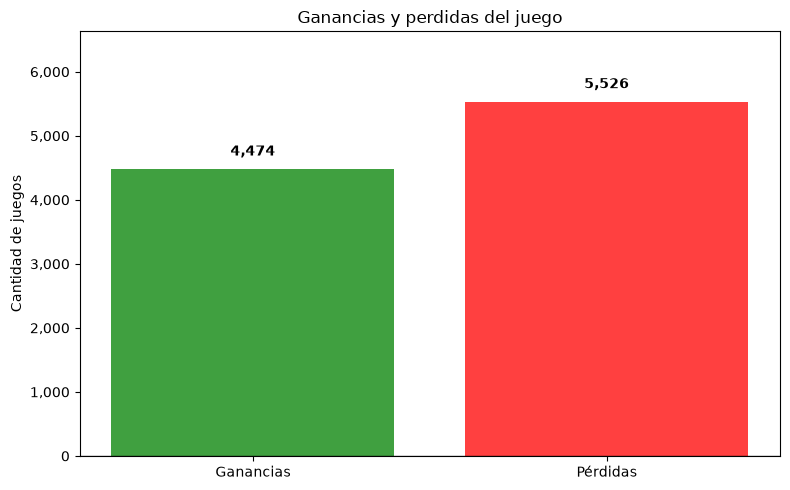

In [444]:
categorias = ["Ganancias", "Pérdidas"]
cantidad_ganancias = int(ganadoras.sum())
cantidad_perdidas = int(perdedoras.sum())
resultado = [cantidad_ganancias, cantidad_perdidas]

plt.figure(figsize=(8, 5))
barras = plt.bar(categorias, resultado, color=["green", "red"], alpha=0.75)
plt.axhline(0, color="black", linewidth=0.9)
plt.title("Ganancias y perdidas del juego")
plt.ylabel("Cantidad de juegos")
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda valor, _: f"{int(valor):,}")
)
limite = max(cantidad_ganancias, cantidad_perdidas) * 1.2
plt.ylim(0, limite)

for barra, cantidad in zip(barras, resultado):
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + limite * 0.025,
        f"{cantidad:,}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

In [445]:
promedio_simulado = df["ganancia"].mean()
saldo_final = df["ganancia_acumulada"].iloc[-1]

print(f"Ganancia promedio simulada por ronda: ${promedio_simulado:.2f}")
print(f"Valor esperado teórico por ronda: ${valor_esperado:.2f}")
print(f"Saldo después de {N:,} rondas: ${saldo_final:,.0f}")
print(f"Probabilidad teórica de ganar una ronda: {probabilidad_ganar_teorica:.2%}")
print(f"Probabilidad teórica de perder una ronda: {probabilidad_perder_teorica:.2%}")

print("\nRecomendación: no conviene jugar en el largo plazo.")
print("Aunque puedes ganar en una ronda, la pérdida esperada es de $5 por ronda.")
print("La simulación muestra un resultado posible; no garantiza el resultado de una sesión futura.")

Ganancia promedio simulada por ronda: $-4.87
Valor esperado teórico por ronda: $-5.00
Saldo después de 10,000 rondas: $-48,670
Probabilidad teórica de ganar una ronda: 44.44%
Probabilidad teórica de perder una ronda: 55.56%

Recomendación: no conviene jugar en el largo plazo.
Aunque puedes ganar en una ronda, la pérdida esperada es de $5 por ronda.
La simulación muestra un resultado posible; no garantiza el resultado de una sesión futura.


RANGO APROXIMADO DE PRECIOS - MONTE CARLO <br>
Como parte del equipo de analistas de grupo "Inversions" se te asigna la <br> tarea de estimar el rango de precios a 30 dias en lo individual para 4 <br> activos, estos activos son: AMAZON, GOOGLE, META Y MICROSOFT. <br>
Se entrega archivo excel llamado "stocks_tickets_tecnologia.xlsx" <br>
Esto debera estimarse con un intervalo de confianza del 95% y se utilizaran <br>
los precios de cierre ajustados. <br>

Que se solicita: <br>
<li> La simulacion de Monte Carlo para esta problematica planteada
<li> Los precios simulados por encima del VaR al 95% de confianza con la grafica que lo represente, colocando ese valor
<li> Quien seria la opcion para minimizar el riesgo de perdida?
<li> El valor esperado(estimado) vs el ultimo precio, esto graficado, para tomar decisiones, sobre quien invertir ya que solo podemos invertir en 1 activo.
<li> La interpretacion y recomendacion, basado y justificado por grafico, histogramas, datos, etc. Donde se demuestre su interpretacion y recomendacion

In [446]:
import pandas as pd
import numpy as np
import datetime as dt
import yfinance as yt
import matplotlib.pyplot as plt
from scipy.stats import norm
import openpyxl as op
import random

In [447]:
excel = pd.read_excel('stocks_tickers_tecnologia.xlsx')

excel

,fecha,AMZN_AC,GOOG_AC,META_AC,MSFT_AC
0,2015-09-22,26.920000,31.058228,92.680946,38.540596
1,2015-09-23,26.803499,31.041767,93.687920,38.514256
2,2015-09-24,26.687500,31.213346,94.126602,38.549374
3,2015-09-25,26.212500,30.523539,92.491516,38.575710
4,2015-09-28,25.202999,29.671631,88.942207,38.005066
...,...,...,...,...,...
2260,2024-09-16,184.889999,158.990005,533.280029,431.339996
2261,2024-09-17,186.880005,160.279999,536.320007,435.149994
2262,2024-09-18,186.429993,160.809998,537.950012,430.809998
2263,2024-09-19,189.869995,163.240005,559.099976,438.690002


In [448]:
def montecarlo_simulation(precios, n_simulaciones=10000, n_days=30, mu=0, sigma=0):
    rng = np.random.default_rng()
    precios_simulados = np.zeros((n_simulaciones, n_days))
    precio_inicial = precios.iloc[-1]
    precios_simulados[:, 0] = precio_inicial

    for dia in range(1, n_days):
        rendimientos = rng.normal(mu, sigma, n_simulaciones)
        precios_simulados[:, dia] = precios_simulados[:, dia - 1] * (1 + rendimientos)

    return precios_simulados

In [449]:
precios = excel.copy()
precios["fecha"] = pd.to_datetime(precios["fecha"])
precios = precios.set_index("fecha").sort_index()
precios.columns = ["AMZN", "GOOG", "META", "MSFT"]
retornos = precios.pct_change().dropna()

activos = list(precios.columns)
n_simulaciones = 10000
n_dias_futuros = 30
simulaciones = {}

for indice, activo in enumerate(activos):
    simulaciones[activo] = montecarlo_simulation(
        precios[activo],
        n_simulaciones=n_simulaciones,
        n_days=n_dias_futuros + 1,
        mu=retornos[activo].mean(),
        sigma=retornos[activo].std(),
    )

print(f"Se simularon {n_simulaciones:,} trayectorias para {n_dias_futuros} dias futuros.")
print("Activos analizados:", ", ".join(activos))

Se simularon 10,000 trayectorias para 30 dias futuros.
Activos analizados: AMZN, GOOG, META, MSFT


In [450]:
resumen_activos = []

for activo in activos:
    precio_actual = precios[activo].iloc[-1]
    precios_finales = simulaciones[activo][:, -1]
    var_precio_95 = np.percentile(precios_finales, 5)
    perdida_potencial = precio_actual - var_precio_95
    perdida_potencial_pct = perdida_potencial / precio_actual

    resumen_activos.append({
        "Activo": activo,
        "Ultimo precio": precio_actual,
        "Precio esperado dia 30": precios_finales.mean(),
        "VaR precio 95%: ": var_precio_95,
        "Perdida potencial: ": perdida_potencial,
        "Perdida potencial: ": perdida_potencial_pct,
        "Probabilidad de superar el precio actual: ": (precios_finales > precio_actual).mean(),
    })

resumen_activos = pd.DataFrame(resumen_activos).set_index("Activo")
resumen_activos.sort_values("Perdida potencial: ")

,Ultimo precio,Precio esperado dia 30,VaR precio 95%:,Perdida potencial:,Probabilidad de superar el precio actual:
Activo,,,,,
MSFT,435.269989,451.863099,386.036519,0.113110,0.6421
GOOG,164.639999,169.265061,143.555826,0.128062,0.5960
AMZN,191.600006,197.655567,163.138068,0.148549,0.5839
META,561.349976,580.279603,461.591037,0.177713,0.5777


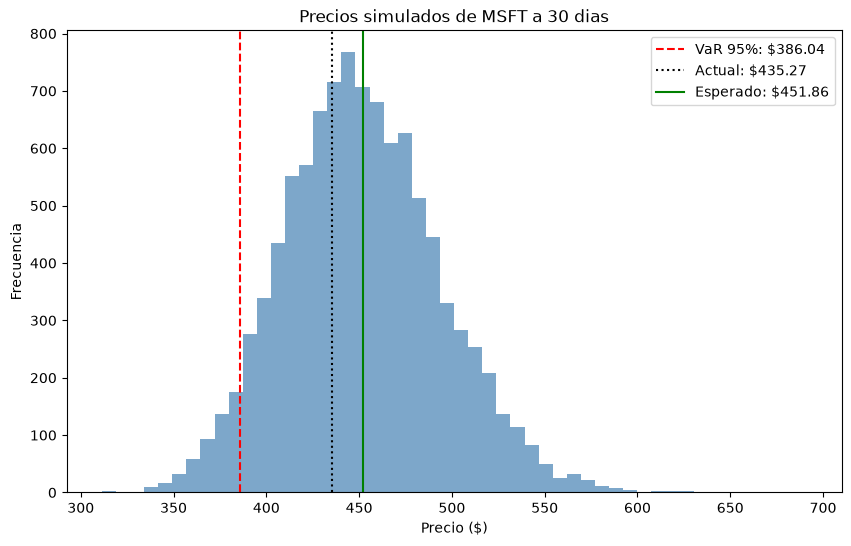

In [451]:
# Histograma sencillo del activo con menor riesgo
activo
precios_finales = simulaciones[activo][:, -1]
precio_actual = precios[activo].iloc[-1]
precio_esperado = precios_finales.mean()
var_95 = np.percentile(precios_finales, 5)

plt.figure(figsize=(10, 6))
plt.hist(precios_finales, bins=50, color="steelblue", alpha=0.7)
plt.axvline(var_95, color="red", linestyle="--", label=f"VaR 95%: ${var_95:.2f}")
plt.axvline(precio_actual, color="black", linestyle=":", label=f"Actual: ${precio_actual:.2f}")
plt.axvline(precio_esperado, color="green", label=f"Esperado: ${precio_esperado:.2f}")
plt.title(f"Precios simulados de {activo} a 30 dias")
plt.xlabel("Precio ($)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

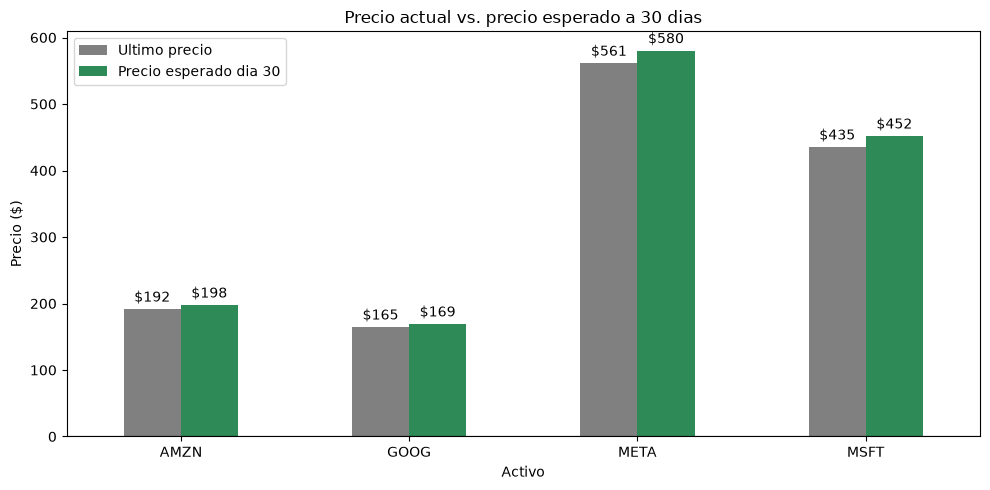

In [452]:
comparacion = resumen_activos[["Ultimo precio", "Precio esperado dia 30"]]
ax = comparacion.plot(kind="bar", figsize=(10, 5), color=["gray", "seagreen"])
ax.set_title("Precio actual vs. precio esperado a 30 dias")
ax.set_xlabel("Activo")
ax.set_ylabel("Precio ($)")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend(loc="upper left")

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="$%.0f", padding=3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
print("Interpretacion:")
print(f"Todos los precios esperados se encuentran por encima del precio actual.")
print(f"{activo} presenta la menor perdida potencial al 95%: "
      f"{resumen_activos.loc[activo, 'Perdida potencial: ']:.2%}.")
print(f"{activo_mayor_valor_esperado} tiene el mayor precio esperado, pero no es la alternativa de menor riesgo.")
print(f"Recomendacion: invertir en {activo} si se prioriza reducir el riesgo de perdida.")

Interpretacion:
Todos los precios esperados se encuentran por encima del precio actual.
MSFT presenta la menor perdida potencial al 95%: 11.31%.
META tiene el mayor precio esperado, pero no es la alternativa de menor riesgo.
Recomendacion: invertir en MSFT si se prioriza reducir el riesgo de perdida.
